# Visualization Exercise Sheet

----------------------------------------------------------

In these short questions we will have you work with data from the GALAH spectroscopic survey (https://www.galah-survey.org) of stars in the Milky Way disk, and practice some visualization techniques to help analyze trends in the data.

You will find helpful documentation and examples to help you make the plots at the following graph galleries.
https://python-graph-gallery.com

https://matplotlib.org/stable/plot_types/index.html

**Download the data file 'galahamr.sav' located in the Moodle exercises page, which contains measurements of physical properties of ~7000 nearby stars.**

In [1]:
%pip install numpy scipy matplotlib
import numpy as np
from matplotlib import pyplot as plt

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [2]:
#Read in data set
from scipy.io import readsav
filepath = 'galahamr.sav'  #change this to the path on your computer where the file is stored
stars = readsav(filepath)  

In [3]:
#Pull out some attributes of the stars we want to look at and store them in arrays
logg = stars['f']['logg']  #surface gravity   
teff = stars['f']['teff']  #effective temperature
mass = stars['f']['massmean']  #mass
lum = mass**4.  #luminosity for stars 0.43 < Msun < 2
age = stars['f']['agemean'] #age
feh = stars['f']['__fe_h_'] #[Fe/H], a logarithmic Iron abundance
afe = stars['f']['__alpha_fe_']  #[Alpha/Fe], logarithmic relative abundance of alpha elements(O, Si, etc.) relative to Iron

### 1) Consider one version of the Hertzsprung-Russell diagram using effective temperature and surface gravity of the stars ( $T_{eff}$, log(g) ).  Make two types of plots of the stars, with clearly labeled axes and colorbars where suitable: 
* a) a scatter plot with the points colored by age 
* b) a 2D density plot using, e.g. the **kde** package along with the **pcolormesh** routine in matplotlib; or hist2d within matplotlib

N = 7066 Sterne


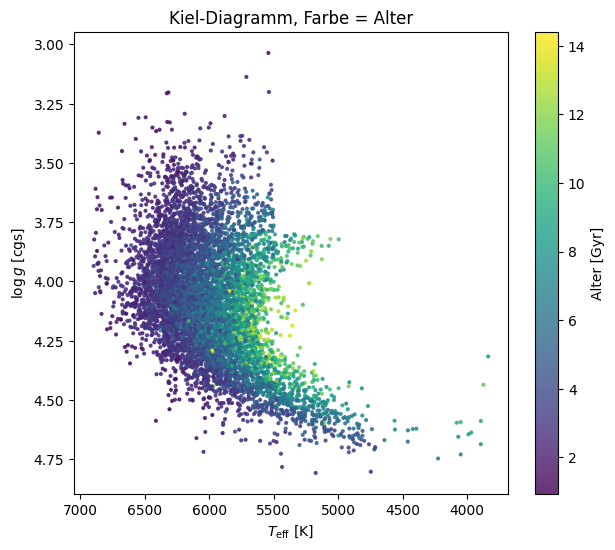

In [4]:
# Aufgabe 1

from scipy.stats import gaussian_kde

logg, teff, mass, lum, age, feh, afe = [np.asarray(a, dtype=float) for a in (logg, teff, mass, lum, age, feh, afe)]
print(f"N = {len(teff)} Sterne")

# 1.a.)

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(teff, logg, c=age, s=4, cmap='viridis', alpha=0.8)
fig.colorbar(sc, ax=ax, label='Alter [Gyr]')
ax.invert_xaxis(); ax.invert_yaxis()   # HRD-Konvention: heiß links, Riesen oben
ax.set_xlabel(r'$T_{\rm eff}$ [K]'); ax.set_ylabel(r'$\log g$ [cgs]')
ax.set_title('Kiel-Diagramm, Farbe = Alter')
plt.show()

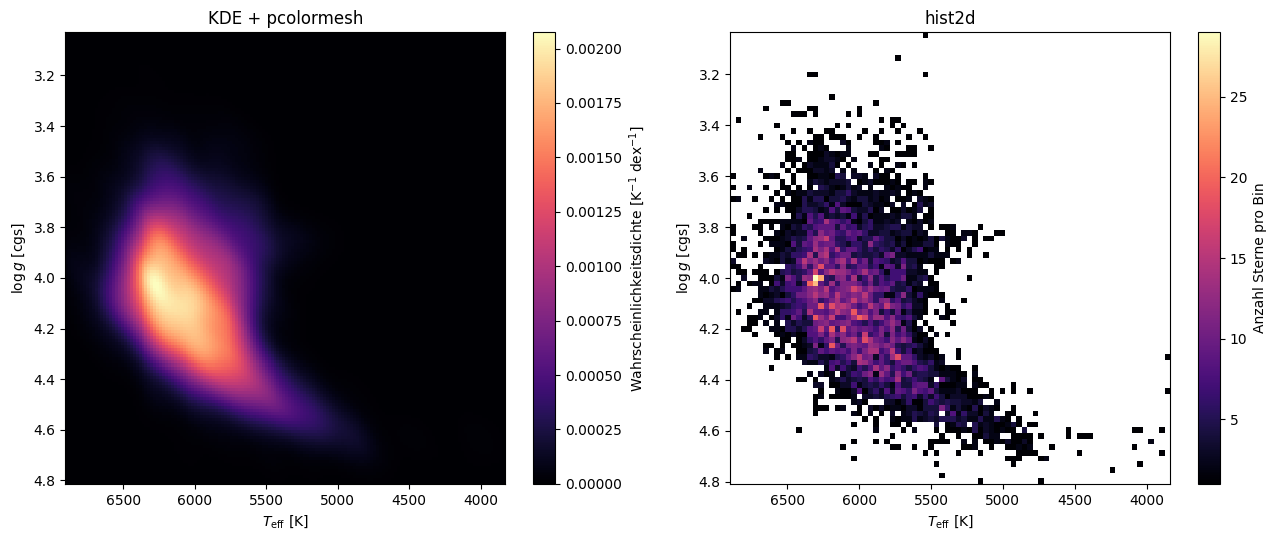

In [5]:
# 1.b.)


tx, gy = (teff - teff.mean())/teff.std(), (logg - logg.mean())/logg.std()
kde = gaussian_kde(np.vstack([tx, gy]))

T = np.linspace(teff.min(), teff.max(), 150)
G = np.linspace(logg.min(), logg.max(), 150)
TT, GG = np.meshgrid(T, G)
Z = kde(np.vstack([((TT - teff.mean())/teff.std()).ravel(),
                   ((GG - logg.mean())/logg.std()).ravel()])).reshape(TT.shape)
trapz = getattr(np, 'trapezoid', getattr(np, 'trapz', None))  # numpy>=2 vs. <2
Z /= trapz(trapz(Z, T, axis=1), G)   # auf Einheiten 1/(K dex) normieren

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))
pm = axs[0].pcolormesh(TT, GG, Z, shading='auto', cmap='magma')
fig.colorbar(pm, ax=axs[0], label=r'Wahrscheinlichkeitsdichte [K$^{-1}$ dex$^{-1}$]')
axs[0].set_title('KDE + pcolormesh')

h = axs[1].hist2d(teff, logg, bins=80, cmap='magma', cmin=1)
fig.colorbar(h[3], ax=axs[1], label='Anzahl Sterne pro Bin')
axs[1].set_title('hist2d')

for ax in axs:
    ax.invert_xaxis(); ax.invert_yaxis()
    ax.set_xlabel(r'$T_{\rm eff}$ [K]'); ax.set_ylabel(r'$\log g$ [cgs]')
plt.tight_layout(); plt.show()

### 2) Use a built-in, or hand-written routine to compute the running average of $T_{eff}$ as a function of $log(g)$.  Overplot this average approximation to the distribution of stars.  It should roughly subdivide the sample into cooler and hotter stars at a given value of $log(g)$.

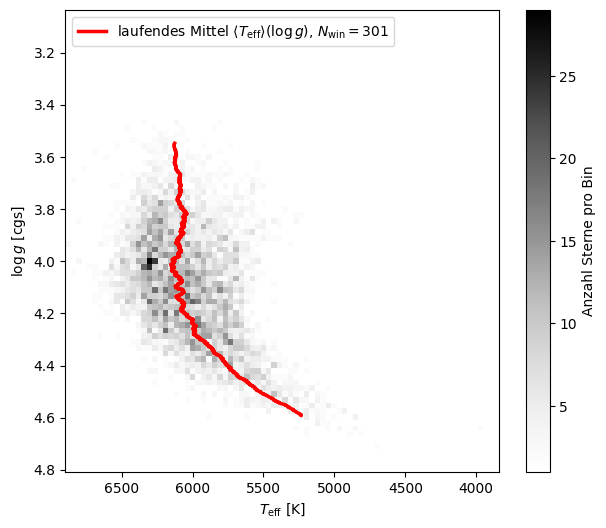

In [6]:
# Aufgabe 2

def running_mean(x, y, window=301):
    """Sortiert nach x und mittelt y über ein gleitendes Fenster aus `window` Sternen."""
    idx = np.argsort(x)
    xs, ys = x[idx], y[idx]
    cs = np.cumsum(np.insert(ys, 0, 0.0))
    ym = (cs[window:] - cs[:-window]) / window
    xm = np.convolve(xs, np.ones(window)/window, mode='valid')   # mittleres x im Fenster
    return xm, ym

logg_rm, teff_rm = running_mean(logg, teff, window=301)

fig, ax = plt.subplots(figsize=(7, 6))
h = ax.hist2d(teff, logg, bins=80, cmap='Greys', cmin=1)
fig.colorbar(h[3], ax=ax, label='Anzahl Sterne pro Bin')
ax.plot(teff_rm, logg_rm, 'r-', lw=2.5, label=r'laufendes Mittel $\langle T_{\rm eff}\rangle(\log g)$, $N_{\rm win}=301$')
ax.invert_xaxis(); ax.invert_yaxis()
ax.set_xlabel(r'$T_{\rm eff}$ [K]'); ax.set_ylabel(r'$\log g$ [cgs]')
ax.legend(loc='upper left'); plt.show()

### 3) [OPTIONAL]  Compute the mean and standard deviation ($\sigma$) of the ages of the cool and hot star sub-samples

* What percent of stars have an age that is within $1-\sigma$ of the mean ages of *both* the cool and hot star sub-samples?  e.g., the fraction of stars that have ages within
 
$(mean(age_{hot}) +\sigma(age_{hot}))$ $\leq age \leq$ $(mean(age_{cool}) -\sigma(age_{cool}))$

heiß: N =  3657, <Alter> = 3.65 Gyr, sigma = 1.16 Gyr
kühl: N =  3409, <Alter> = 6.77 Gyr, sigma = 2.31 Gyr

Intervall laut Angabe: [4.81, 4.46] Gyr
Anteil im Intervall: 0.0 %
Schnitt beider 1-sigma-Bereiche: [4.46, 4.81] Gyr -> 5.5 % aller Sterne


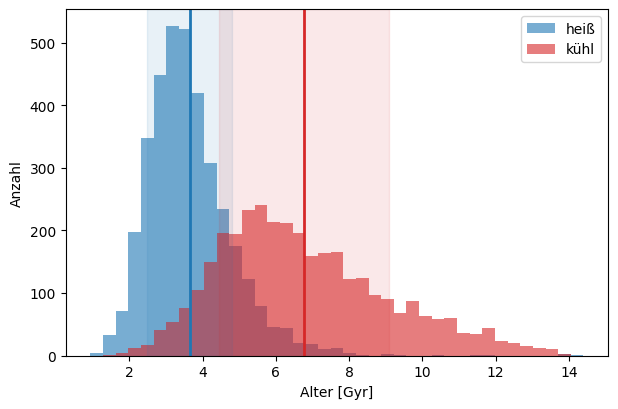

In [7]:
# Aufgabe 3


teff_ref = np.interp(logg, logg_rm, teff_rm)   # außerhalb des Bereichs: Randwert
hot, cool = teff > teff_ref, teff <= teff_ref

mu_h, sd_h = age[hot].mean(),  age[hot].std()
mu_c, sd_c = age[cool].mean(), age[cool].std()
print(f"heiß: N = {hot.sum():5d}, <Alter> = {mu_h:.2f} Gyr, sigma = {sd_h:.2f} Gyr")
print(f"kühl: N = {cool.sum():5d}, <Alter> = {mu_c:.2f} Gyr, sigma = {sd_c:.2f} Gyr")

# Intervall laut Aufgabe: mean_hot + sigma_hot <= age <= mean_cool - sigma_cool
lo, hi = mu_h + sd_h, mu_c - sd_c
print(f"\nIntervall laut Angabe: [{lo:.2f}, {hi:.2f}] Gyr")
frac = np.mean((age >= lo) & (age <= hi)) if lo <= hi else 0.0
print(f"Anteil im Intervall: {100*frac:.1f} %")

# Allgemeiner (Schnitt der beiden 1-sigma-Bereiche, unabhängig von der Reihenfolge):
lo2, hi2 = max(mu_h - sd_h, mu_c - sd_c), min(mu_h + sd_h, mu_c + sd_c)
frac2 = np.mean((age >= lo2) & (age <= hi2))
print(f"Schnitt beider 1-sigma-Bereiche: [{lo2:.2f}, {hi2:.2f}] Gyr -> {100*frac2:.1f} % aller Sterne")

fig, ax = plt.subplots(figsize=(7, 4.5))
bins = np.linspace(age.min(), age.max(), 40)
ax.hist(age[hot],  bins, alpha=0.6, color='tab:blue', label='heiß')
ax.hist(age[cool], bins, alpha=0.6, color='tab:red',  label='kühl')
for m, s, c in [(mu_h, sd_h, 'tab:blue'), (mu_c, sd_c, 'tab:red')]:
    ax.axvline(m, color=c, lw=2); ax.axvspan(m-s, m+s, color=c, alpha=0.1)
ax.set_xlabel('Alter [Gyr]'); ax.set_ylabel('Anzahl'); ax.legend(); plt.show()

**Interpretation:** Bei festem $\log g$ sind heißere Sterne massereicher und damit jünger (kürzere Lebensdauer auf der Hauptreihe / dem Unterriesenast), kühlere sind älter – daher $\langle {\rm age}_{\rm hot}\rangle < \langle {\rm age}_{\rm cool}\rangle$. Ob das Intervall aus der Angabe überhaupt existiert, hängt davon ab, ob die beiden 1σ-Bereiche *auseinander* liegen ($\mu_h+\sigma_h \le \mu_c-\sigma_c$). Sind die Verteilungen breit und überlappen stark, ist das Intervall leer und der sinnvolle Wert ist der Anteil im Schnitt der beiden 1σ-Bereiche (zweite Zahl oben).

Hier: $\mu_h+\sigma_h \approx 4.81$ Gyr $> \mu_c-\sigma_c \approx 4.46$ Gyr – das Intervall wie angegeben ist also **leer (0 %)**. Im Überlappungsbereich [4.46, 4.81] Gyr, der in *beiden* 1σ-Bereichen liegt, befinden sich **≈ 5.5 %** der Sterne.

### 4) Create two versions of a *weighted* 2D density distribution of the sample of stars in the plane of **[Fe/H]** as a function of **age**:
* a) One where the density distribution is weighted by the mass of the stars
* b) One where the density distribution is weighted by the luminosity of the stars

Compute the weighted average metallicity and age for both cases and indicate them on the density distributions.

Masse       : <Alter> = 4.89 Gyr, <[Fe/H]> = -0.048
Leuchtkraft : <Alter> = 4.15 Gyr, <[Fe/H]> = -0.026
ungewichtet : <Alter> = 5.15 Gyr, <[Fe/H]> = -0.057


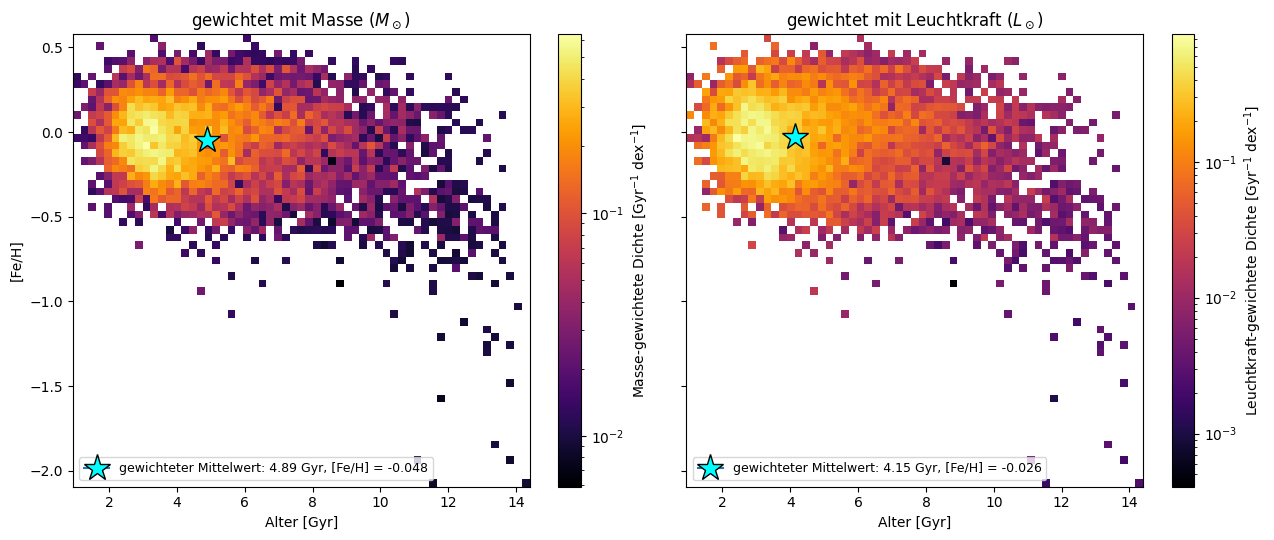

In [8]:
# Aufgabe 4


bins = [np.linspace(age.min(), age.max(), 60), np.linspace(feh.min(), feh.max(), 60)]

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, w, name, unit in [(axs[0], mass, 'Masse', r'$M_\odot$'),
                          (axs[1], lum,  'Leuchtkraft', r'$L_\odot$')]:
    h = ax.hist2d(age, feh, bins=bins, weights=w, density=True, cmap='inferno',
                  norm=plt.matplotlib.colors.LogNorm())
    fig.colorbar(h[3], ax=ax, label=f'{name}-gewichtete Dichte [Gyr$^{{-1}}$ dex$^{{-1}}$]')
    age_w, feh_w = np.average(age, weights=w), np.average(feh, weights=w)
    ax.plot(age_w, feh_w, marker='*', ms=20, mfc='cyan', mec='k',
            label=fr'gewichteter Mittelwert: {age_w:.2f} Gyr, [Fe/H] = {feh_w:.3f}')
    ax.set_title(f'gewichtet mit {name} ({unit})')
    ax.set_xlabel('Alter [Gyr]'); ax.legend(loc='lower left', fontsize=9)
    print(f"{name:12s}: <Alter> = {age_w:.2f} Gyr, <[Fe/H]> = {feh_w:.3f}")
axs[0].set_ylabel('[Fe/H]')
print(f"{'ungewichtet':12s}: <Alter> = {age.mean():.2f} Gyr, <[Fe/H]> = {feh.mean():.3f}")
plt.tight_layout(); plt.show()

**Interpretation:** Die Gewichtung mit $L\propto M^4$ hebt massereiche Sterne extrem hervor. Diese sind jung und tendenziell metallreich, daher verschiebt sich der leuchtkraftgewichtete Mittelwert zu kleinerem Alter und höherem [Fe/H] als der massengewichtete. Das illustriert, warum aus integriertem Licht bestimmte Alter/Metallizitäten von Sternpopulationen jünger wirken als die tatsächliche (massengewichtete) Population.